In [178]:
# for package auto reload
%load_ext autoreload
%autoreload 2

%matplotlib inline

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [179]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Data Anylysis
### EDA and Preprocessing

In [180]:
dataset_path = "hotel_bookings.csv"
df = pd.read_csv(dataset_path, delimiter=',', low_memory=False)

df.head(7)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03
5,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03
6,Resort Hotel,0,0,2015,July,27,1,0,2,2,...,No Deposit,NaN,NaN,0,Transient,107.0,0,0,Check-Out,2015-07-03


In [181]:
df.shape

(119390, 32)

In [182]:
df.columns

Index(['hotel', 'is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_month', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies', 'meal',
       'country', 'market_segment', 'distribution_channel',
       'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'reserved_room_type',
       'assigned_room_type', 'booking_changes', 'deposit_type', 'agent',
       'company', 'days_in_waiting_list', 'customer_type', 'adr',
       'required_car_parking_spaces', 'total_of_special_requests',
       'reservation_status', 'reservation_status_date'],
      dtype='str')

In [183]:
df = df.rename(columns ={"adr": "price_per_night"})
df.columns

Index(['hotel', 'is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_month', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies', 'meal',
       'country', 'market_segment', 'distribution_channel',
       'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'reserved_room_type',
       'assigned_room_type', 'booking_changes', 'deposit_type', 'agent',
       'company', 'days_in_waiting_list', 'customer_type', 'price_per_night',
       'required_car_parking_spaces', 'total_of_special_requests',
       'reservation_status', 'reservation_status_date'],
      dtype='str')

In [184]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

In [185]:
values0, values1 = df['is_canceled'].value_counts()
percentage0, percentage1 = df['is_canceled'].value_counts(normalize=True) #Normalized to have the percentage 

print(f"# canceled bookings: {values1} and # not canceled bookings: {values0}")
print (f"Percentage of canceled bookings: {percentage0:.2f}%")
print (f"Percentage of not canceled bookings: {percentage1:.2f}%")



# canceled bookings: 44224 and # not canceled bookings: 75166
Percentage of canceled bookings: 0.63%
Percentage of not canceled bookings: 0.37%


In [186]:
# Checking number of different values in country column
df['country'].value_counts()

country
PRT    48590
GBR    12129
FRA    10415
ESP     8568
DEU     7287
       ...  
NCL        1
KIR        1
SDN        1
ATF        1
SLE        1
Name: count, Length: 177, dtype: int64

### Null values

In [187]:
def display_null(df):
        null = df.isnull().sum().sort_values(ascending=False)
        for x in null.index:
            if null[x] > 0:
                print(f"{x}: {null[x]/len(df)*100:.4f}% missing values")

        if null.sum() == 0:
            print("No missing values in the dataset")
        
       
  
display_null(df)


company: 94.3069% missing values
agent: 13.6862% missing values
country: 0.4087% missing values
children: 0.0034% missing values


In [188]:
#First create a column called "Booked through company" with 0 and 1 ,0 for no and 1 for yes.
#Then drop company column since it has 94.3% missing values
df["has_company"] = df["company"].notnull().astype(int)
df = df.drop(columns=['company'])

# Fill missing values in agent column with 0 since it is a categorical variable
df['agent'] = df['agent'].fillna(0).astype(str)

# Fill missing values in country column with 'Unknown'
df['country'] = df['country'].fillna('Unknown')

# Fill missing values in children column with 0 since it's less than 1%
df['children'] = df['children'].fillna(0).astype(int)


In [189]:
#check the null values again
display_null(df)

No missing values in the dataset


### Wiered values 

In [190]:
df["price_per_night"].describe()

count    119390.000000
mean        101.831122
std          50.535790
min          -6.380000
25%          69.290000
50%          94.575000
75%         126.000000
max        5400.000000
Name: price_per_night, dtype: float64

In [191]:
# First count rows with impossible prices
negative = (df["price_per_night"] < 0).sum()
too_high = (df["price_per_night"] > 1000).sum()
zero = (df["price_per_night"] == 0).sum()

print(f"Negative ADR: {negative} rows")
print(f"ADR above 1000: {too_high} rows")
print(f"ADR equal to 0: {zero} rows")

Negative ADR: 1 rows
ADR above 1000: 1 rows
ADR equal to 0: 1959 rows


In [192]:
# Now drop the rows with 0, negative, and too high prices
df = df[(df["price_per_night"] >= 0) & (df["price_per_night"] <= 1000)]

### Data leakage <br>


In [193]:
# Dropping: 
# reservation_status takes the values Canceled / Check-Out / No-Show. It is the answer. 
# reservation_status_date is the date that status was set, so it’s only known after the outcome. 
# assigned_room_type is decided at check-in, which is after the booking.
df = df.drop(columns=['reservation_status', 'reservation_status_date','assigned_room_type'])

### Column choice

In [200]:
# creating a total night column by adding the number of weekend nights and the number of week nights
df['total_nights']= df['stays_in_weekend_nights'] + df['stays_in_week_nights']
print(df['total_nights'].head(5)) #checking

# Group countries that represent less than 1% of booking into a single category called "Other"
n = 0.01*len(df)
counts = df['country'].value_counts()
rare_countries = counts[counts < n].index
df['country'] = df['country'].replace(rare_countries, 'Other')
print('number of differnt country values = ', df['country'].nunique()) # cheking

# Creating a new column called "arrival_week_of_month", using "arrival_date_day_of_month" to know which week of the month the arrival date falls into.
df["arrival_week_of_month"] = ((df["arrival_date_day_of_month"] - 1) // 7 + 1).clip(upper=4)
# and dropping the "arrival_date_day_of_month" column since for example week of 52 means the same as first week of month .
df = df.drop(columns=['arrival_date_day_of_month'])


0    0
1    0
2    1
3    1
4    2
Name: total_nights, dtype: int64
number of differnt country values =  15


### Tran and Validation set

The data was split randomly into training (60%), validation (20%) and test (20%) sets so bookings from 2015-2017 are mixed across all three sets.

In [201]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['is_canceled'])
Y = df['is_canceled']

# First split 20% of the data into a test set
x_temp, x_test, y_temp, y_test = train_test_split( X, Y, test_size=0.20, stratify=Y, random_state=42)

# Then split the remaining 80% into a training set and a validation set (60% train, 20% validation)
x_train, x_val, y_train, y_val = train_test_split(x_temp, y_temp, test_size=0.25, stratify=y_temp, random_state=42)

print(f"Training set: {len(x_train)} rows\nValidation set: {len(x_val)} rows\nTest set: {len(x_test)} rows")


Training set: 71632 rows
Validation set: 23878 rows
Test set: 23878 rows


### Numberical and Categorical columns of training data

In [202]:
num_cols = x_train.select_dtypes(include="number").columns.tolist()
cat_cols = x_train.select_dtypes(exclude="number").columns.tolist()

print("Numerical:", num_cols)
print("Categorical:", cat_cols)

Numerical: ['lead_time', 'arrival_date_year', 'arrival_date_week_number', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'days_in_waiting_list', 'price_per_night', 'required_car_parking_spaces', 'total_of_special_requests', 'has_company', 'total_nights', 'arrival_week_of_month']
Categorical: ['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'deposit_type', 'agent', 'customer_type']


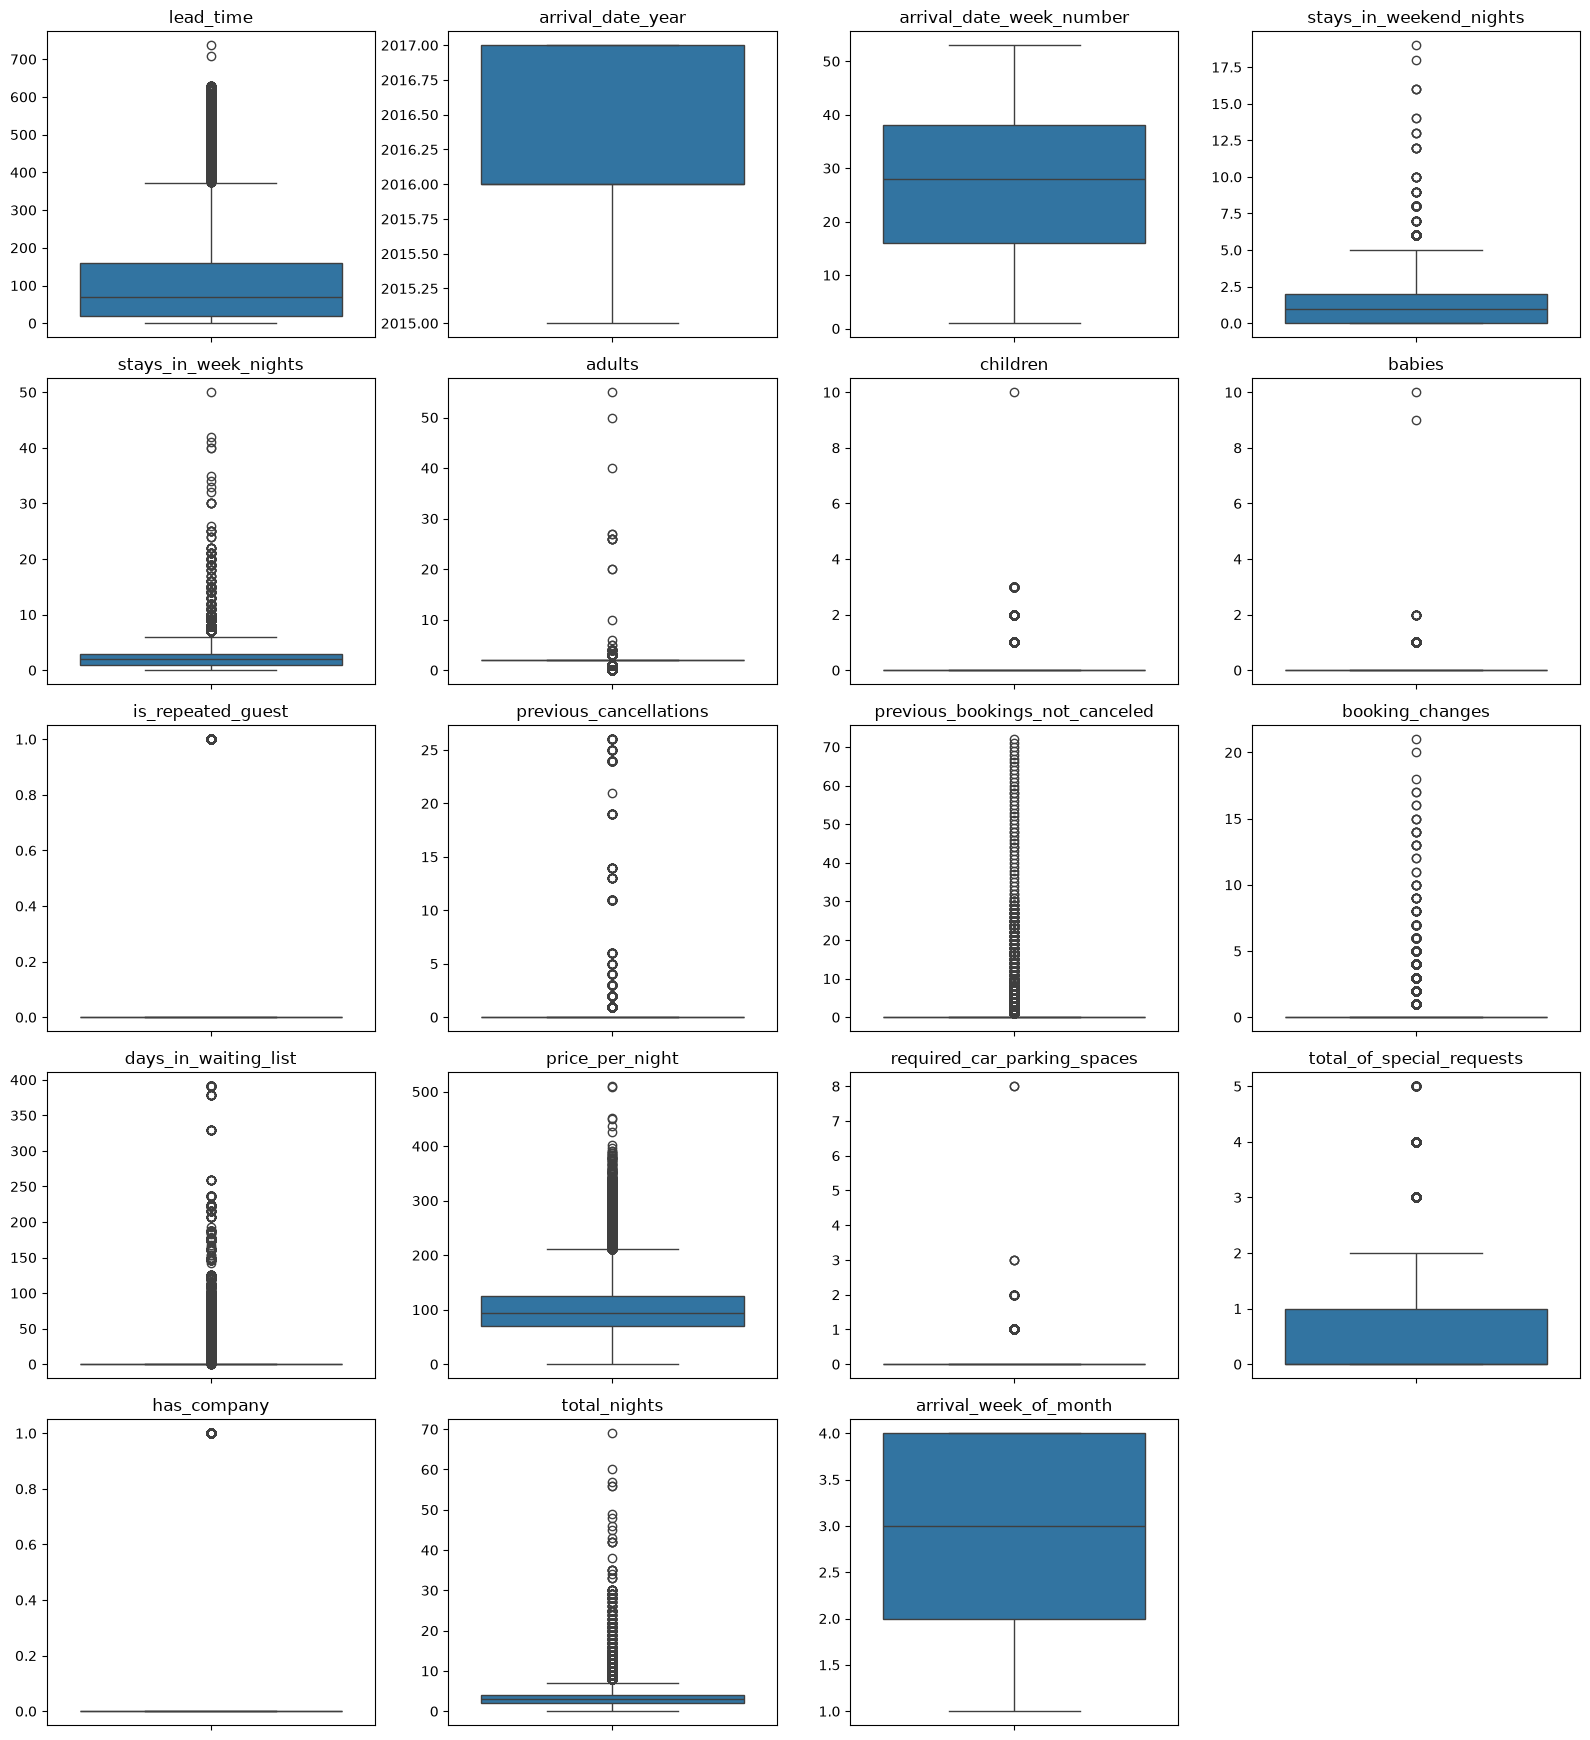

In [207]:
n_cols = 4
n_rows = -(-len(num_cols) // n_cols)   # rounds up

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 3.5 * n_rows))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.boxplot(y=df[col], ax=axes[i])
    axes[i].set_title(col)
    axes[i].set_ylabel("")

for j in range(len(num_cols), len(axes)):   # hide empty plots
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

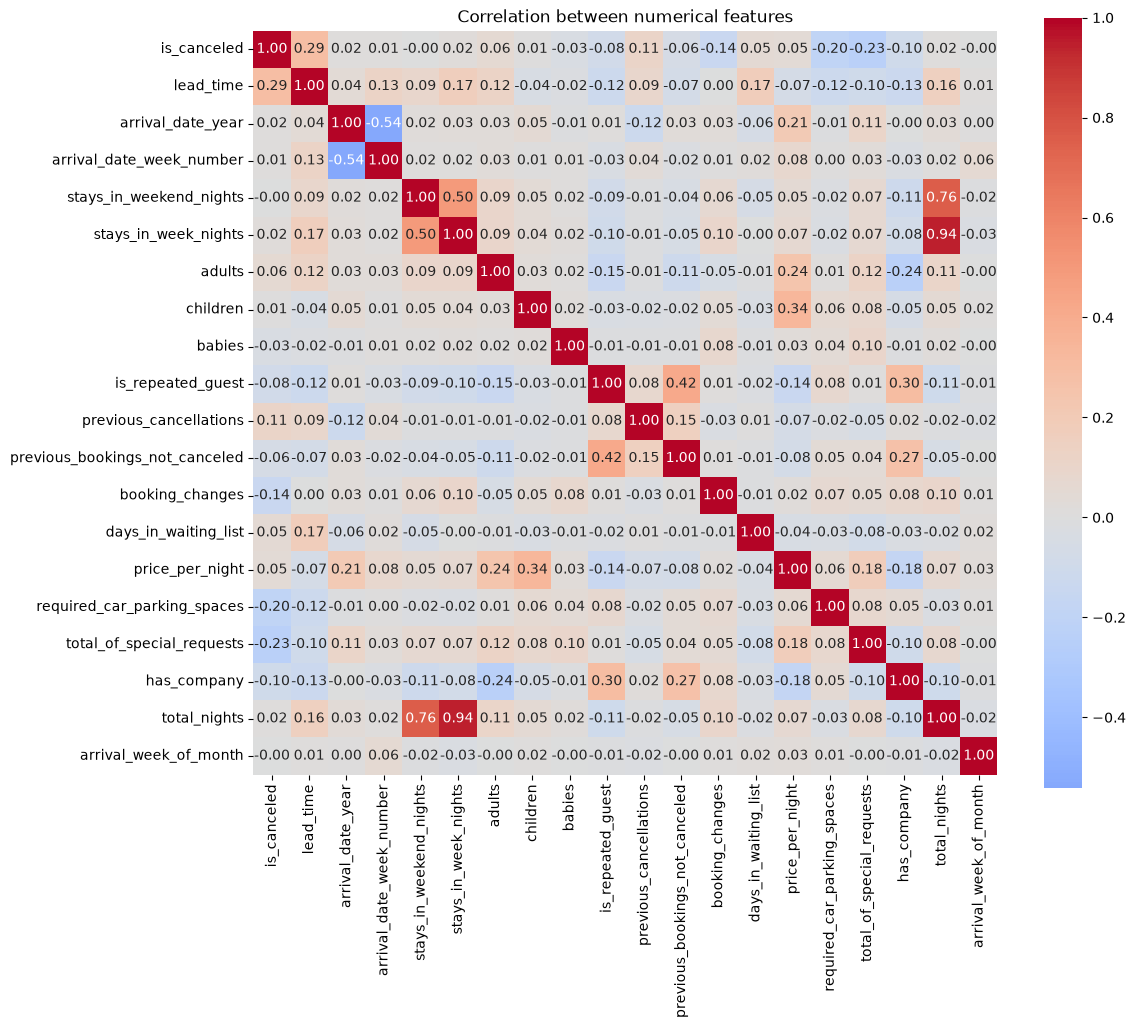

In [208]:
corr = df.select_dtypes(include="number").corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation between numerical features")
plt.show()

In [209]:
print(corr["is_canceled"].drop("is_canceled").sort_values(ascending=False).round(3))

lead_time                         0.293
previous_cancellations            0.110
adults                            0.060
days_in_waiting_list              0.054
price_per_night                   0.049
stays_in_week_nights              0.025
total_nights                      0.018
arrival_date_year                 0.017
arrival_date_week_number          0.008
children                          0.005
stays_in_weekend_nights          -0.002
arrival_week_of_month            -0.004
babies                           -0.032
previous_bookings_not_canceled   -0.057
is_repeated_guest                -0.085
has_company                      -0.099
booking_changes                  -0.144
required_car_parking_spaces      -0.195
total_of_special_requests        -0.235
Name: is_canceled, dtype: float64
